__Tasks:__
- [x] Collect a MVD (Minimum Viable Data)
    - I'm using the raw data for MOLM-13 screen from this [bioRxiv](https://www.biorxiv.org/content/10.1101/2022.12.14.518457v1)
- [x] Trim reads in FASTQ, count unique sequences, and map to V2 sgRNA library table.
- [ ] Compare with ScreenProcessing

# Collect data
A Minimum Viable Data (MVD)!

In [1]:
# import subprocess 

In [2]:
# %%bash 
# mkdir -p molm13_exp_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v2/molm13_exp`; do
#     b=`basename $fq`;
#     gsutil cp $fq molm13_exp_fastq/$b;
# done

# Count FASTQ ...

In [ ]:
import matplotlib.pyplot as plt

In [1]:
import sys

sys.path.append('../../../ScreenPro2/')

from screenpro import ngs

In [2]:
import pandas as pd

### 

### 

In [16]:
library = pd.read_csv('../../../ScreenPro2/library_tables/CRISPRi_v2_human_librarytable.txt.gz',sep='\t')
library = library.drop_duplicates('sequence',keep='first').set_index('sequence')

In [46]:
import anndata as ad

import polars as pl

from time import time

from glob import glob

### Get Counts

In [41]:
counts = {}

for fq_file in glob('molm13_exp_fastq/*'):
    sample_id = fq_file.split('/')[1].split('.')[0]
    
    print(f"\033[1m{sample_id}\033[0m")
    
    df_cnt = ngs.fastq_to_count_unique_seq(fq_file,n_bp_from_5p=20).to_pandas()
    count_df = ngs.map_sample_counts_to_library(library,df_cnt)
    
    counts[sample_id] = count_df

GSK_Rep2
load FASTQ file as a Polars DataFrame
done in 31.135s
Count unique sequences
done in 0.696s
% mapped sequences: 0.83
% non-mapped sequences: 0.17
DMSO_Rep2
load FASTQ file as a Polars DataFrame
done in 30.947s
Count unique sequences
done in 0.709s
% mapped sequences: 0.83
% non-mapped sequences: 0.17
T0_Rep1
load FASTQ file as a Polars DataFrame
done in 30.062s
Count unique sequences
done in 0.700s
% mapped sequences: 0.84
% non-mapped sequences: 0.16
DAC_Rep1
load FASTQ file as a Polars DataFrame
done in 29.467s
Count unique sequences
done in 0.684s
% mapped sequences: 0.83
% non-mapped sequences: 0.17
DMSO_Rep1
load FASTQ file as a Polars DataFrame
done in 34.229s
Count unique sequences
done in 0.767s
% mapped sequences: 0.83
% non-mapped sequences: 0.17
DAC_Rep2
load FASTQ file as a Polars DataFrame
done in 27.846s
Count unique sequences
done in 0.634s
% mapped sequences: 0.83
% non-mapped sequences: 0.17
GSK_Rep1
load FASTQ file as a Polars DataFrame
done in 30.321s
Count 

### Make `AnnData`

In [57]:
counts_df = pd.concat(dict([(name,df['counts']) for name, df in counts.items()]),axis=1)

In [118]:
adata = ad.AnnData(X=counts_df.T,var=library)

adata = adata[:,adata.to_df().sum().gt(50)].copy()

### Compare counts with ScreenProcessing

In [119]:
# !wget 'https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/molm13_exp/mergedcountstable.txt'

In [120]:
screenprocessing_counts = pd.read_csv(
    'mergedcountstable.txt', 
    sep='\t', 
    header=list(range(2)),
    index_col=list(range(1))
)

In [121]:
from venn import venn

<AxesSubplot: >

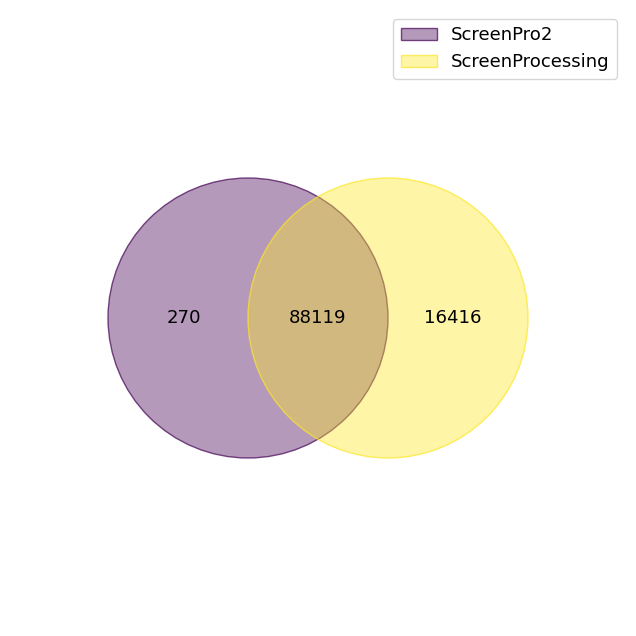

In [122]:
venn({
    'ScreenPro2':set(adata.var.sgId),
    'ScreenProcessing':set(screenprocessing_counts.index)#.loc[adata.var.sgId,:]
})

In [94]:
# adata.var.sgId.to_list()

In [95]:
# screenprocessing_counts#.loc[adata.var.sgId,:]

In [66]:
def plot_count_benchmark():
    pass
    #screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

In [68]:
plot_count_benchmark()

# 